#Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import plotly.express as ex

###Import csv File to analysis

In [ ]:
df=pd.read_csv("/content/financial_loan.csv")
df.head()


,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,11/02/2021,13/09/2021,13/04/2021,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,01/01/2021,14/12/2021,15/01/2021,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,05/01/2021,12/12/2021,09/01/2021,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,25/02/2021,12/12/2021,12/03/2021,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,01/01/2021,14/12/2021,15/01/2021,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


In [ ]:
df.shape

(38576, 24)

In [ ]:
df.describe()

,id,member_id,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
count,3.857600e+04,3.857600e+04,3.857600e+04,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000
mean,6.810371e+05,8.476515e+05,6.964454e+04,0.133274,326.862965,0.120488,11296.066855,22.132544,12263.348533
std,2.113246e+05,2.668105e+05,6.429368e+04,0.066662,209.092000,0.037164,7460.746022,11.392282,9051.104777
min,5.473400e+04,7.069900e+04,4.000000e+03,0.000000,15.690000,0.054200,500.000000,2.000000,34.000000
25%,5.135170e+05,6.629788e+05,4.150000e+04,0.082100,168.450000,0.093200,5500.000000,14.000000,5633.000000
50%,6.627280e+05,8.473565e+05,6.000000e+04,0.134200,283.045000,0.118600,10000.000000,20.000000,10042.000000
75%,8.365060e+05,1.045652e+06,8.320050e+04,0.185900,434.442500,0.145900,15000.000000,29.000000,16658.000000
max,1.077501e+06,1.314167e+06,6.000000e+06,0.299900,1305.190000,0.245900,35000.000000,90.000000,58564.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38576 entries, 0 to 38575
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     38576 non-null  int64  
 1   address_state          38576 non-null  object 
 2   application_type       38576 non-null  object 
 3   emp_length             38576 non-null  object 
 4   emp_title              37138 non-null  object 
 5   grade                  38576 non-null  object 
 6   home_ownership         38576 non-null  object 
 7   issue_date             38576 non-null  object 
 8   last_credit_pull_date  38576 non-null  object 
 9   last_payment_date      38576 non-null  object 
 10  loan_status            38576 non-null  object 
 11  next_payment_date      38576 non-null  object 
 12  member_id              38576 non-null  int64  
 13  purpose                38576 non-null  object 
 14  sub_grade              38576 non-null  object 
 15  te

###Convert data type from object to Datetime for dates columns

In [ ]:
df['issue_date']=pd.to_datetime(df['issue_date'],format="%d/%m/%Y")


In [ ]:
df['last_credit_pull_date']=pd.to_datetime(df['last_credit_pull_date'],format="%d/%m/%Y")
df['last_payment_date']=pd.to_datetime(df['last_payment_date'],format="%d/%m/%Y")
df['next_payment_date']=pd.to_datetime(df['next_payment_date'],format="%d/%m/%Y")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38576 entries, 0 to 38575
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     38576 non-null  int64         
 1   address_state          38576 non-null  object        
 2   application_type       38576 non-null  object        
 3   emp_length             38576 non-null  object        
 4   emp_title              37138 non-null  object        
 5   grade                  38576 non-null  object        
 6   home_ownership         38576 non-null  object        
 7   issue_date             38576 non-null  datetime64[ns]
 8   last_credit_pull_date  38576 non-null  datetime64[ns]
 9   last_payment_date      38576 non-null  datetime64[ns]
 10  loan_status            38576 non-null  object        
 11  next_payment_date      38576 non-null  datetime64[ns]
 12  member_id              38576 non-null  int64         
 13  p

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
id,0
address_state,0
application_type,0
emp_length,0
emp_title,1438
grade,0
home_ownership,0
issue_date,0
last_credit_pull_date,0
last_payment_date,0


In [ ]:
df['emp_title'].fillna("Unknown",inplace=True)

/tmp/ipykernel_2597/1383426498.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['emp_title'].fillna("Unknown",inplace=True)


##Total Loan Applications

In [ ]:
total_Loan_Applications=df['id'].count()
print("Total Loan Applications are : ",total_Loan_Applications)

Total Loan Applications are :  38576


###MTD Total Loan Applications

In [ ]:
latest_issue_date=df['issue_date'].max()
latest_year=latest_issue_date.year
latest_month=latest_issue_date.month

mtd_data=df[(df['issue_date'].dt.year==latest_year)&(df['issue_date'].dt.month==latest_month)]
mtd_total_Loan_Applications=mtd_data['id'].count()
print(f"MTD Loan Applications (for {latest_issue_date.strftime('%B %Y')}):{mtd_total_Loan_Applications}")


MTD Loan Applications (for December 2021):4314


### Total Funded Amount

In [ ]:
total_Funded_Amount=df['loan_amount'].sum()
total_Funded_Amount_Millions=total_Funded_Amount /1000000
print("Total Funded Loan Amount are : ${:.2f}M ".format(total_Funded_Amount_Millions))

Total Funded Loan Amount are : $435.76M 


###MTD Total Funded Amount

In [ ]:
latest_issue_date=df['issue_date'].max()
latest_year=latest_issue_date.year
latest_month=latest_issue_date.month

mtd_data=df[(df['issue_date'].dt.year==latest_year)&(df['issue_date'].dt.month==latest_month)]

mtd_total_Funded_Amount=mtd_data['loan_amount'].sum()
mtd_total_Funded_Amount_millions=mtd_total_Funded_Amount/1000000
print("MTD Funded Amount is: ${:.2f}M".format(mtd_total_Funded_Amount_millions))

MTD Funded Amount is: $53.98M


###Total Amount Received

In [ ]:
total_Amount_Received =df['total_payment'].sum()
total_Amount_Received_millions=total_Amount_Received /1000000
print("Total Received Amount is : ${:.2f}M ".format(total_Amount_Received_millions))

Total Received Amount is : $473.07M 


###MTD Total Received Amount

In [ ]:
latest_issue_date=df['issue_date'].max()
latest_year=latest_issue_date.year
latest_month=latest_issue_date.month

mtd_data=df[(df['issue_date'].dt.year==latest_year)&(df['issue_date'].dt.month==latest_month)]

mtd_total_Amount_Received=mtd_data['total_payment'].sum()
mtd_Amount_Received_millions=mtd_total_Amount_Received/1000000
print("MTD Amount Recieved is: ${:.2f}M".format(mtd_Amount_Received_millions))

MTD Amount Recieved is: $58.07M


###Average Interest Rate

In [ ]:
average_interstRate=df['int_rate'].mean()
average_interstRate_per=(average_interstRate*100)
print("Average Interest Rate is :{:.2f}%".format(average_interstRate_per))

Average Interest Rate is :12.05%


###MTD Average Interest Rate

In [ ]:
latest_issue_date=df['issue_date'].max()
latest_year=latest_issue_date.year
latest_month=latest_issue_date.month

mtd_data=df[(df['issue_date'].dt.year==latest_year)&(df['issue_date'].dt.month==latest_month)]
mtd_avg_rate=mtd_data['int_rate'].mean()
mtd_avg_rate_per=mtd_avg_rate*100
print("MTD average Rate is :{:.2f}%".format(mtd_avg_rate_per))

MTD average Rate is :12.36%


###Average DTI(Debt-To-Income) Ratio

In [ ]:
avg_dti=df['dti'].mean()
avg_dti_per=avg_dti*100
print("Average DTI Ratio is: {:.2f}%".format(avg_dti_per))

Average DTI Ratio is: 13.33%


###MTD Average DTI Ratio

In [ ]:
latest_issue_date=df['issue_date'].max()
latest_year=latest_issue_date.year
latest_month=latest_issue_date.month

mtd_data=df[(df['issue_date'].dt.year==latest_year)&(df['issue_date'].dt.month==latest_month)]
mtd_avg_dti=mtd_data['dti'].mean()
mtd_avg_dti_per=mtd_avg_dti*100
print("MTD average DTI Ratio is :{:.2f}%".format(mtd_avg_dti_per))

MTD average DTI Ratio is :13.67%


In [ ]:
pd.set_option('display.max_columns',None)

###Good Loan Data

In [ ]:
good_loan=df.loc[df['loan_status'].isin(["Fully Paid","Current"])]
good_loan

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,loan_status,next_payment_date,member_id,purpose,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,Fully Paid,2021-02-15,1288686,car,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,Fully Paid,2021-04-12,1272024,car,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,Fully Paid,2021-02-15,1302971,car,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835
5,1062608,CA,INDIVIDUAL,3 years,Studio 94 Corp,C,RENT,2021-07-17,2021-03-16,2021-08-12,Fully Paid,2021-09-12,1294481,car,C3,36 months,Not Verified,28000.0,0.1260,275.96,0.1465,8000,11,8637
6,1067441,TX,INDIVIDUAL,10+ years,American Airlines,C,MORTGAGE,2021-11-19,2021-06-14,2021-12-13,Fully Paid,2022-01-13,1301833,car,C2,36 months,Verified,94800.0,0.2453,205.86,0.1427,6000,30,7218
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38571,803452,NJ,INDIVIDUAL,< 1 year,Joseph M Sanzari Company,C,MORTGAGE,2021-07-11,2021-05-16,2021-05-16,Current,2021-06-16,992381,wedding,C1,60 months,Verified,100000.0,0.1986,551.64,0.1299,24250,33,31946
38572,970377,NY,INDIVIDUAL,8 years,Swat Fame,C,RENT,2021-10-11,2021-04-16,2021-05-16,Current,2021-06-16,1192039,wedding,C1,60 months,Verified,50000.0,0.0458,579.72,0.1349,25200,18,31870
38573,875376,CA,INDIVIDUAL,5 years,Anaheim Regional Medical Center,D,RENT,2021-09-11,2021-05-16,2021-05-16,Current,2021-06-16,1089898,wedding,D5,60 months,Verified,65000.0,0.1734,627.93,0.1749,25000,20,35721
38574,972997,NY,INDIVIDUAL,5 years,Brooklyn Radiology,D,RENT,2021-10-11,2021-05-16,2021-05-16,Current,2021-06-16,1194971,wedding,D5,60 months,Verified,368000.0,0.0009,612.72,0.1825,24000,9,33677


###Good Loan Application percentage

In [ ]:
Good_Loan_Percentage=(good_loan['id'].count()/df['id'].count())*100
print("Good Loan Application Percentage :{:.2f}%".format(Good_Loan_Percentage))

Good Loan Application Percentage :86.18%


###Total Good Loan Applications

In [ ]:
print("Total Good Loan Applications :{:,}".format(good_loan['id'].count()))

Total Good Loan Applications :33,243


###Good Loan Funded Amount

In [ ]:
Good_Loan_Funded=good_loan['loan_amount'].sum()
Good_Loan_Funded_Millions=Good_Loan_Funded/1000000
print("Total Good Loan Funded Amount :${:.2f}M".format(Good_Loan_Funded_Millions))

Total Good Loan Funded Amount :$370.22M


###Good Loan Received Amount

In [ ]:
Good_Loan_Received_Amount=good_loan['total_payment'].sum()
Good_Loan_Received_Millions=Good_Loan_Received_Amount/1000000
print("Total Good Loan Received Amount :${:.2f}M".format(Good_Loan_Received_Millions))

Total Good Loan Received Amount :$435.79M


###Bad Loan Data

In [ ]:
Bad_Loan=df.loc[df['loan_status']=="Charged Off"]
Bad_Loan

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,loan_status,next_payment_date,member_id,purpose,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,Charged Off,2021-05-13,1314167,car,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,Charged Off,2021-02-09,1304116,car,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
8,1065254,FL,INDIVIDUAL,10+ years,Tech Data Corp,A,MORTGAGE,2021-09-02,2021-06-15,2021-10-12,Charged Off,2021-11-12,1299335,car,A5,36 months,Verified,116400.0,0.0394,762.08,0.0890,24000,31,8650
11,1062734,CA,INDIVIDUAL,3 years,myrvpartsplace.com,B,RENT,2021-09-11,2021-03-13,2021-10-12,Charged Off,2021-11-12,1295018,car,B4,36 months,Not Verified,75000.0,0.2288,374.26,0.1242,11200,13,4225
15,1060995,RI,INDIVIDUAL,< 1 year,HSA-UWC,B,RENT,2021-12-11,2021-02-14,2021-10-13,Charged Off,2021-11-13,1292578,car,B4,36 months,Source Verified,60000.0,0.0630,400.99,0.1242,12000,14,9547
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38488,521184,MA,INDIVIDUAL,2 years,The Danvers Butchery,D,RENT,2021-05-10,2021-09-15,2021-05-12,Charged Off,2021-06-12,673936,wedding,D5,60 months,Verified,16000.0,0.1001,116.91,0.1607,4800,5,2807
38489,605855,NJ,INDIVIDUAL,2 years,Vericrest Financial Inc,D,RENT,2021-11-10,2021-05-14,2021-01-14,Charged Off,2021-02-14,777229,wedding,D5,60 months,Verified,72000.0,0.1372,289.09,0.1557,12000,25,11022
38490,550598,MA,INDIVIDUAL,10+ years,Wendys OFH of New York Inc,E,RENT,2021-07-10,2021-07-13,2021-03-13,Charged Off,2021-04-13,709676,wedding,E1,60 months,Verified,45000.0,0.0256,368.37,0.1645,15000,10,11582
38491,682280,PA,INDIVIDUAL,2 years,Williams Residential,E,RENT,2021-03-11,2021-04-12,2021-12-11,Charged Off,2022-01-11,871421,wedding,E1,60 months,Verified,70000.0,0.0864,858.59,0.1640,35000,39,8667


###Bad Loan Application Percentage

In [ ]:
Bad_Loan_Percentage=(Bad_Loan['id'].count()/df['id'].count())*100
print("Bad Loan Application Percentage :{:.2f}%".format(Bad_Loan_Percentage))

Bad Loan Application Percentage :13.82%


###Total Bad Loan Applications

In [ ]:
print("Total Bad Loan Applications :{:,}".format(Bad_Loan['id'].count()))

Total Bad Loan Applications :5,333


###Bad Loan Total Funded Amount

In [ ]:
Bad_Loan_Funded=Bad_Loan['loan_amount'].sum()
Bad_Loan_Funded_Millions=Bad_Loan_Funded/1000000
print("Total Bad Loan Funded Amount :${:.2f}M".format(Bad_Loan_Funded_Millions))

Total Bad Loan Funded Amount :$65.53M


###Bad Loan Total Received Amount

In [ ]:
Bad_Loan_Received=Bad_Loan['total_payment'].sum()
Bad_Loan_Received_Millions=Bad_Loan_Received/1000000
print("Total Bad Loan Funded Amount :${:.2f}M".format(Bad_Loan_Received_Millions))

Total Bad Loan Funded Amount :$37.28M


According to Loan Status Some Stats are here

In [ ]:
Loan_stat=df.groupby('loan_status').agg(total_Loan_Applications=('id','count'),total_funded_amount=('loan_amount','sum'),total_Received_amount=('total_payment','sum'),Average_Interest_rate=('int_rate','mean'),Average_DTI_Ratio=('dti','mean'))
Loan_stat

,total_Loan_Applications,total_funded_amount,total_Received_amount,Average_Interest_rate,Average_DTI_Ratio
loan_status,,,,,
Charged Off,5333,65532225,37284763,0.138786,0.140047
Current,1098,18866500,24199914,0.150993,0.147243
Fully Paid,32145,351358350,411586256,0.116411,0.131674


###Monthly trends By Issue Date

In [ ]:
new_df=df.copy()
new_df

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,loan_status,next_payment_date,member_id,purpose,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,Charged Off,2021-05-13,1314167,car,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,Fully Paid,2021-02-15,1288686,car,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,Charged Off,2021-02-09,1304116,car,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,Fully Paid,2021-04-12,1272024,car,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,Fully Paid,2021-02-15,1302971,car,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38571,803452,NJ,INDIVIDUAL,< 1 year,Joseph M Sanzari Company,C,MORTGAGE,2021-07-11,2021-05-16,2021-05-16,Current,2021-06-16,992381,wedding,C1,60 months,Verified,100000.0,0.1986,551.64,0.1299,24250,33,31946
38572,970377,NY,INDIVIDUAL,8 years,Swat Fame,C,RENT,2021-10-11,2021-04-16,2021-05-16,Current,2021-06-16,1192039,wedding,C1,60 months,Verified,50000.0,0.0458,579.72,0.1349,25200,18,31870
38573,875376,CA,INDIVIDUAL,5 years,Anaheim Regional Medical Center,D,RENT,2021-09-11,2021-05-16,2021-05-16,Current,2021-06-16,1089898,wedding,D5,60 months,Verified,65000.0,0.1734,627.93,0.1749,25000,20,35721
38574,972997,NY,INDIVIDUAL,5 years,Brooklyn Radiology,D,RENT,2021-10-11,2021-05-16,2021-05-16,Current,2021-06-16,1194971,wedding,D5,60 months,Verified,368000.0,0.0009,612.72,0.1825,24000,9,33677


In [ ]:
new_df['Month']=new_df['issue_date'].dt.month
new_df.head()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,loan_status,next_payment_date,member_id,purpose,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment,MonthName,Month
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,Charged Off,2021-05-13,1314167,car,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009,February,2
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,Fully Paid,2021-02-15,1288686,car,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939,January,1
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,Charged Off,2021-02-09,1304116,car,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522,January,1
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,Fully Paid,2021-04-12,1272024,car,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911,February,2
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,Fully Paid,2021-02-15,1302971,car,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835,January,1


In [ ]:
new_df['MonthName']=new_df['issue_date'].dt.month_name()
new_df.head()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,loan_status,next_payment_date,member_id,purpose,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment,Month,MonthName
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,Charged Off,2021-05-13,1314167,car,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009,2,February
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,Fully Paid,2021-02-15,1288686,car,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939,1,January
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,Charged Off,2021-02-09,1304116,car,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522,1,January
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,Fully Paid,2021-04-12,1272024,car,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911,2,February
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,Fully Paid,2021-02-15,1302971,car,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835,1,January


###Monthly All 3 Metrics Presented

In [ ]:
monthly_trend=new_df.groupby(['Month','MonthName']).agg(total_Loan_Applications=('id','count'),total_funded_amount=('loan_amount','sum'),total_Received_amount=('total_payment','sum'))
monthly_Trend=monthly_trend.sort_values('Month',ascending=True)
monthly_Trend

,,total_Loan_Applications,total_funded_amount,total_Received_amount
Month,MonthName,,,
1,January,2332,25031650,27578836
2,February,2279,24647825,27717745
3,March,2627,28875700,32264400
4,April,2755,29800800,32495533
5,May,2911,31738350,33750523
6,June,3184,34161475,36164533
7,July,3366,35813900,38827220
8,August,3441,38149600,42682218
9,September,3536,40907725,43983948


Monthly Trend by Issue Date

In [ ]:
monthly_Trend

,,total_Loan_Applications,total_funded_amount,total_Received_amount
Month,MonthName,,,
1,January,2332,25031650,27578836
2,February,2279,24647825,27717745
3,March,2627,28875700,32264400
4,April,2755,29800800,32495533
5,May,2911,31738350,33750523
6,June,3184,34161475,36164533
7,July,3366,35813900,38827220
8,August,3441,38149600,42682218
9,September,3536,40907725,43983948


In [ ]:
monthly_trend_proper=monthly_Trend.copy()

In [ ]:
monthly_trend_proper=monthly_trend_proper.reset_index()

In [ ]:
monthly_trend_proper

,Month,MonthName,total_Loan_Applications,total_funded_amount,total_Received_amount
0,1,January,2332,25031650,27578836
1,2,February,2279,24647825,27717745
2,3,March,2627,28875700,32264400
3,4,April,2755,29800800,32495533
4,5,May,2911,31738350,33750523
5,6,June,3184,34161475,36164533
6,7,July,3366,35813900,38827220
7,8,August,3441,38149600,42682218
8,9,September,3536,40907725,43983948
9,10,October,3796,44893800,49399567


All three Metrics Monthly Trend Visuallization

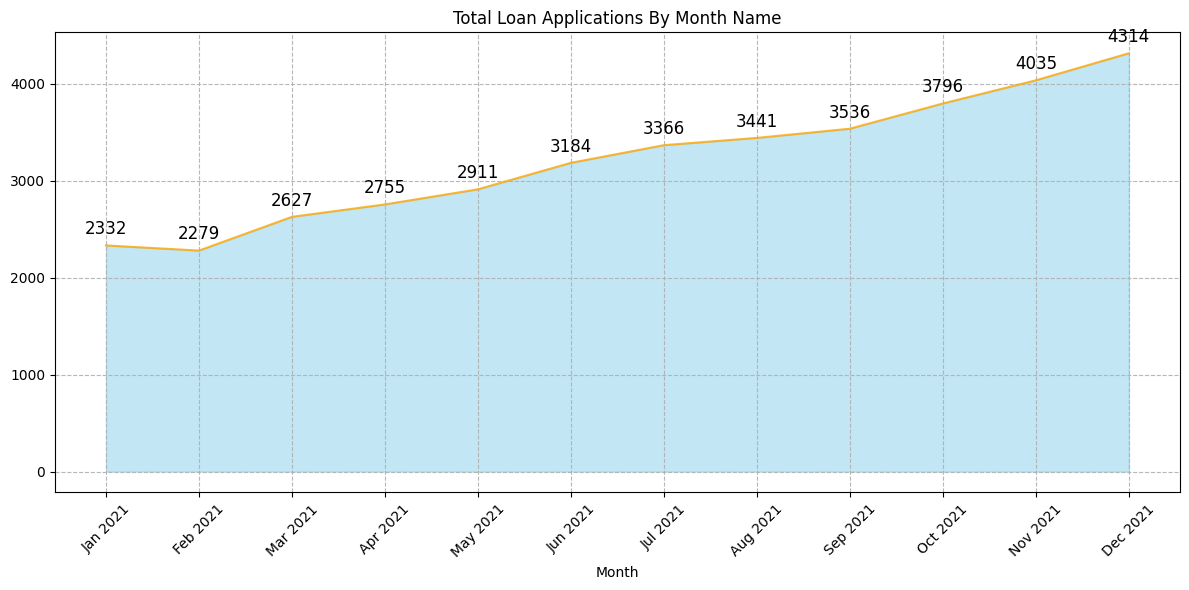

In [ ]:
monthly_application=df.sort_values('issue_date').assign(month_name=lambda x : x['issue_date'].dt.strftime('%b %Y')).groupby('month_name',sort=False)['id'].count().reset_index(name='loan_application_count')
plt.figure(figsize=(12,6))
plt.fill_between(monthly_application['month_name'],monthly_application['loan_application_count'],color='skyblue',alpha=0.5)
plt.plot(monthly_application['month_name'],monthly_application['loan_application_count'],color='orange',alpha=0.8)
for x,y in zip(monthly_application['month_name'],monthly_application['loan_application_count']):
  plt.annotate(f'{y:.0f}',(x,y),textcoords='offset points',xytext=(0,8),ha="center",fontsize=12)
plt.title("Total Loan Applications By Month Name")
plt.xlabel("Month")
plt.xticks(ticks=range(len(monthly_application)),labels=monthly_application['month_name'],rotation=45)
plt.tight_layout()
plt.grid(True,linestyle='--',alpha=0.9)
plt.show()

<Figure size 1200x600 with 0 Axes>

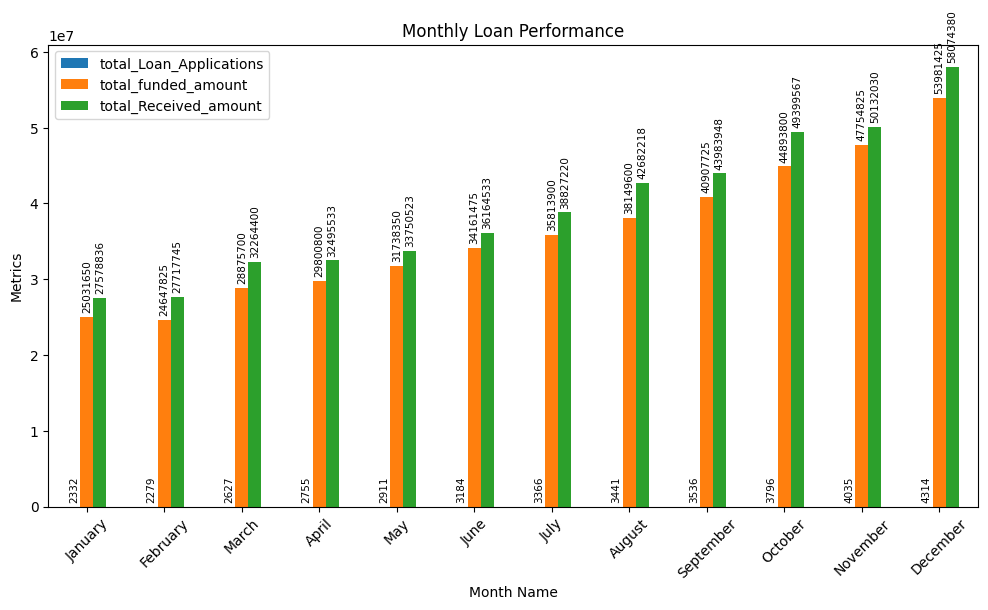

In [ ]:
plt.figure(figsize=(12,6))
axx=monthly_trend_proper.plot(
    x='MonthName',
    y=['total_Loan_Applications',
       'total_funded_amount',
       'total_Received_amount'],
    kind='bar',
    figsize=(12,6)
)

for container in axx.containers:
    axx.bar_label(container, padding=3, fmt='%.0f', fontsize=7.5,rotation=90)
plt.xlabel('Month Name')
plt.ylabel('Metrics')
plt.xticks(rotation=45)
plt.title('Monthly Loan Performance')
plt.legend()

Monthly Trend  by Total Loan Applications

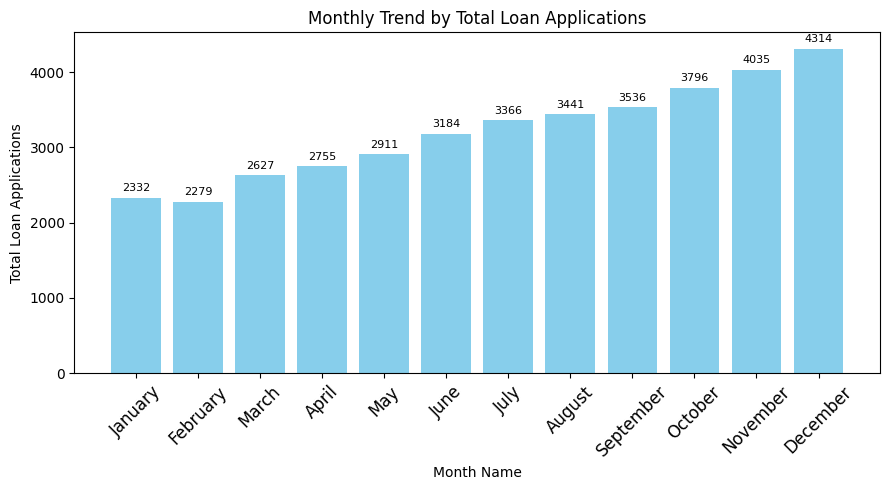

In [ ]:
plt.figure(figsize=(9,5))
ax=plt.bar(x=monthly_trend_proper['MonthName'],
height=monthly_trend_proper['total_Loan_Applications'],color='skyblue')
plt.bar_label(ax, padding=3, fmt='%.0f', fontsize=8)
plt.title("Monthly Trend by Total Loan Applications")
plt.xticks(rotation=45,fontsize=12)
plt.xlabel("Month Name")
plt.ylabel("Total Loan Applications")
plt.tight_layout()
plt.show()

Monthly Trend  by Total Funded Amount

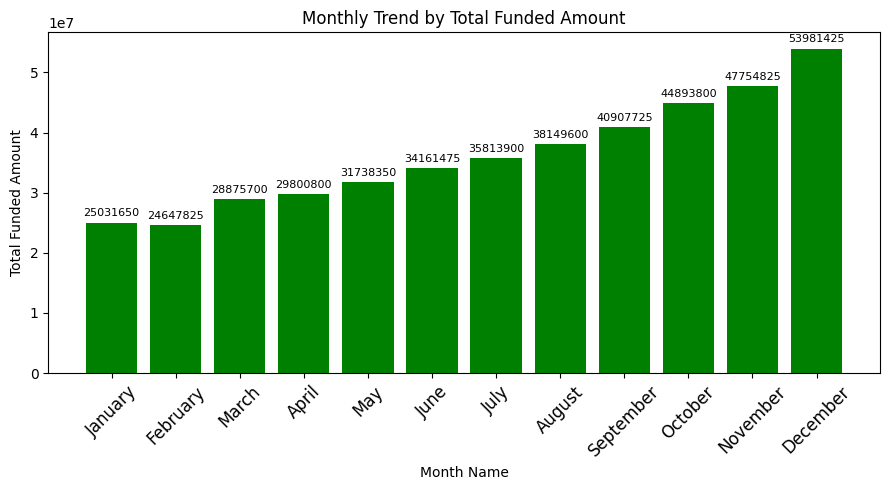

In [ ]:
plt.figure(figsize=(9,5))
ax=plt.bar(x=monthly_trend_proper['MonthName'],
height=monthly_trend_proper['total_funded_amount'],color='green')
plt.bar_label(ax, padding=3, fmt='%.0f', fontsize=8)
plt.title("Monthly Trend by Total Funded Amount")
plt.xticks(rotation=45,fontsize=12)
plt.xlabel("Month Name")
plt.ylabel("Total Funded Amount")
plt.tight_layout()
plt.show()

Monthly Trend  by Total Received Amount

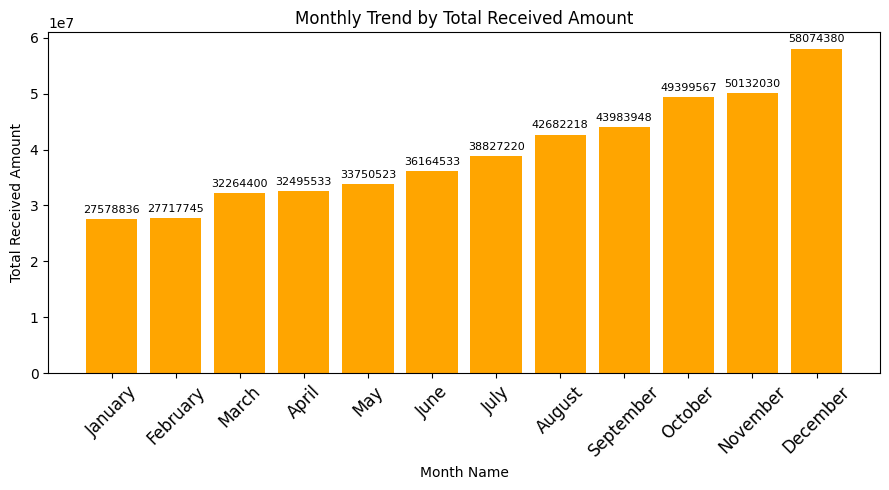

In [ ]:
plt.figure(figsize=(9,5))
ax=plt.bar(x=monthly_trend_proper['MonthName'],
height=monthly_trend_proper['total_Received_amount'],color='orange')
plt.bar_label(ax, padding=3, fmt='%.0f', fontsize=8)
plt.title("Monthly Trend by Total Received Amount")
plt.xticks(rotation=45,fontsize=12)
plt.xlabel("Month Name")
plt.ylabel("Total Received Amount")
plt.tight_layout()
plt.show()

###Regional State wise Total Funded Amount

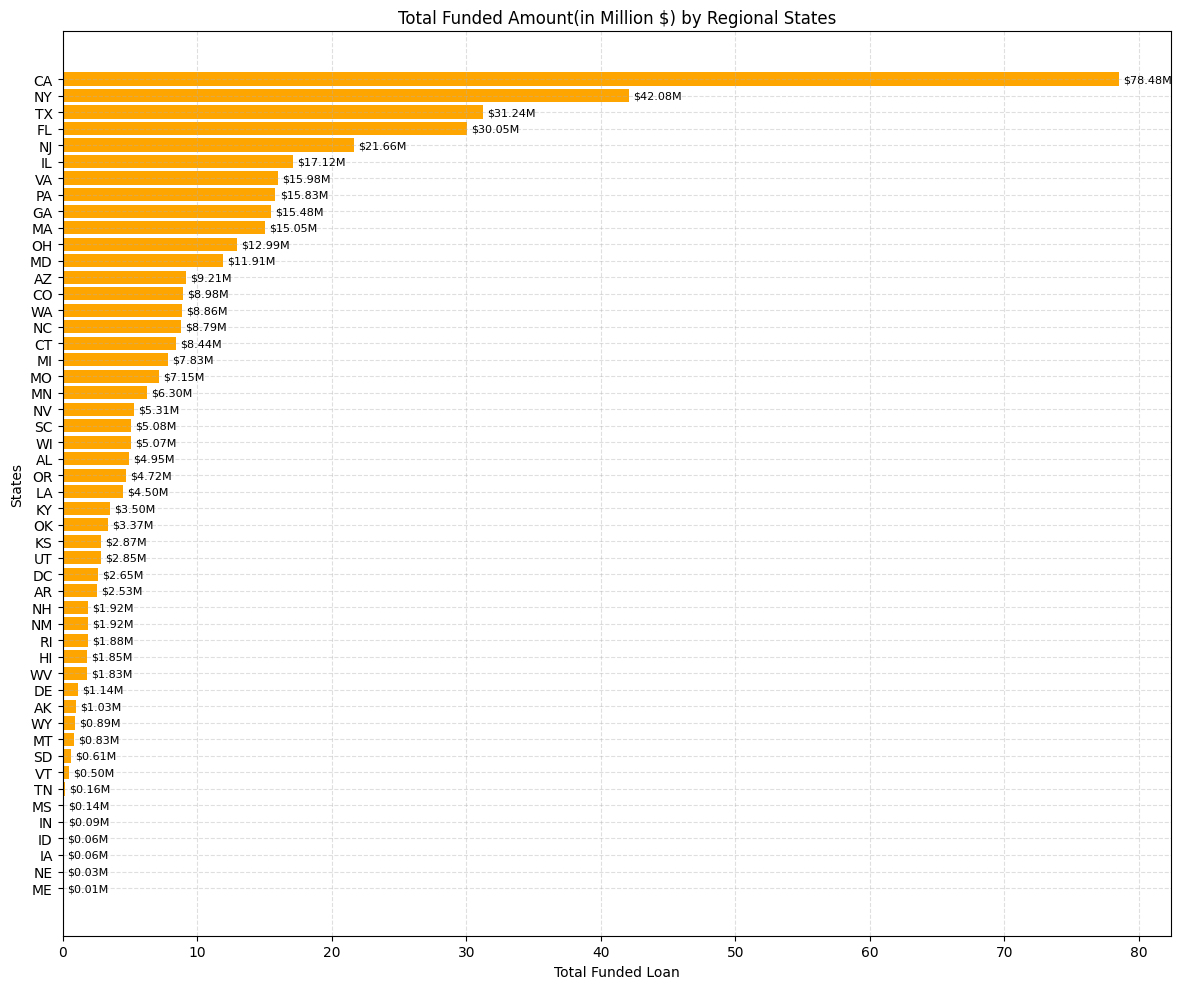

In [ ]:
state_wise_Funded_data=df.groupby('address_state',sort=False)['loan_amount'].sum().sort_values(ascending=True)
state_wise_Funded_data_millions=state_wise_Funded_data/1000000
plt.figure(figsize=(12,10))
axx=plt.barh(state_wise_Funded_data_millions.index,state_wise_Funded_data_millions.values,color='orange')
plt.bar_label(axx,padding=3,fmt='$%.2fM',fontsize=8)
plt.title("Total Funded Amount(in Million $) by Regional States")
plt.xlabel("Total Funded Loan")
plt.ylabel("States")
plt.grid(True,linestyle='--',alpha=0.4)
plt.tight_layout()
plt.show()

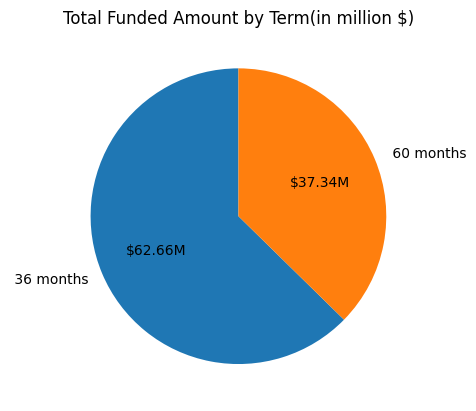

In [ ]:
term_funding_Data=df.groupby('term')['loan_amount'].sum()
plt.pie(term_funding_Data/1000000,startangle=90,autopct='$%.2fM',labels=term_funding_Data.index)
plt.title("Total Funded Amount by Term(in million $)")
plt.show()